# CHE1147 FINAL PROJECT Early Prediction of Lithium-Ion Battery Cycle Life from the First 100 Cycles

Predict the total cycle life of a lithium-ion cell using only measurements from its first 100 charge–discharge cycles, so that long life tests could be shortened.

Inputs: features computed from cycles 1–100.
Target: cycle life, modelled as log10(cycle life).

### Dataset
MATR dataset, standardized version from **BatteryLife** (Tan et al., KDD 2025), downloaded from Zenodo (`MATR.zip` and `Life labels.zip`).

- 169 commercial 18650 cylindrical cells, LiFePO4 (LFP) cathode / graphite anode, nominal capacity 1.1 Ah
- cycled at 30 °C with 81 different fast-charging protocols and identical discharge protocols
- original data: https://data.matr.io/1/projects/5c48dd2bc625d700019f3204 and https://data.matr.io/1/projects/5d80e633f405260001c0b60a/batches/5dcef1fe110002c7215b2c94

Original papers to cite:
- Severson et al., *Data-driven prediction of battery cycle life before capacity degradation*, Nature Energy (2019)
- Attia et al., *Closed-loop optimization of fast-charging protocols for batteries with machine learning*, Nature (2020)

### How to run
1. Put `MATR.zip` and `Life labels.zip` in a Google Drive folder `MyDrive/CHE1147/` (or, to run locally, unzip them into the repository's `data/` folder and set `USE_COLAB = False` in Section 1.2; see the README).
2. Run all cells from top to bottom (**Runtime → Run all**). The first run unzips the data, which takes a few minutes.


## 1. Setup
### 1.1 Imports
All libraries used in the notebook are imported here

In [1]:
# Standard library
from pathlib import Path
import json
import pickle
import shutil, zipfile

#Data handling and plotting
import numpy as np
import pandas as pd
import seaborn as sns #Statistical plots (histograms, heatmap)
import matplotlib.pyplot as plt #General plotting

#Scikit-learn: Data splitting, cross-validation and tuning
from sklearn.model_selection import train_test_split #80/20 train/test split
from sklearn.model_selection import KFold #shared 5-fold cross-validation splits
from sklearn.model_selection import RepeatedKFold #repeated CV (summary table)
from sklearn.model_selection import GridSearchCV #hyperparameter tuning with CV
from sklearn.model_selection import cross_val_predict  #out-of-fold CV predictions
from sklearn.model_selection import cross_val_score   #CV scores (summary table)

# Scikit-learn: preprocessing and pipelines
from sklearn.preprocessing import StandardScaler #rescale features to mean 0, standard deviation 1
from sklearn.pipeline import make_pipeline #chain scaler + model so scaling is redone inside each CV fold

# Scikit-learn: models ---
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, ElasticNet #Linear models
from sklearn.ensemble import RandomForestRegressor

#Scikit-learn: evaluation and interpretation
from sklearn.metrics import mean_absolute_error #MAE
from sklearn.metrics import mean_squared_error #MSE (RMSE = square root of MSE)
from sklearn.metrics import mean_absolute_percentage_error #MAPE

from sklearn.inspection import permutation_importance  #Feature importance for random forest
from sklearn.base import clone

### 1.2 Data location

In [2]:
USE_COLAB = True

In [3]:
if USE_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ZIP_DIR = Path('/content/drive/MyDrive/CHE1147')
    DATA_ROOT = Path('/content/data') #where the data is unzipped (Colab's fast local disk)
    EXPECTED_PKL = 169 #MATR has 169 batteries

    def count_pkl():
        #number of battery files currently unzipped
        return len(list(DATA_ROOT.rglob('MATR_*.pkl')))

    labels_ok = (DATA_ROOT / 'Life labels' / 'MATR_labels.json').exists()

    #Re-extract if ANYTHING is missing
    if count_pkl() != EXPECTED_PKL or not labels_ok:
        print(f'Found {count_pkl()} of {EXPECTED_PKL} battery files -> extracting from scratch (a few minutes)...')
        shutil.rmtree(DATA_ROOT, ignore_errors=True)
        DATA_ROOT.mkdir(parents=True)
        for name in ['MATR.zip', 'Life labels.zip']:
            src = ZIP_DIR / name
            assert src.exists(), f'{src} not found. Check ZIP_DIR points to the folder holding the zips.'
            local = Path('/content') / name
            shutil.copy(src, local)
            with zipfile.ZipFile(local) as zf:
                zf.extractall(DATA_ROOT)
                for info in zf.infolist():
                    out = DATA_ROOT / info.filename
                    if not info.is_dir():
                        assert out.stat().st_size == info.file_size, f'Incomplete file: {info.filename}'
            local.unlink()

    #final checks: all 169 battery files and the label file must be present
    assert count_pkl() == EXPECTED_PKL, f'Only {count_pkl()} battery files found, expected {EXPECTED_PKL}.'
    assert (DATA_ROOT / 'Life labels' / 'MATR_labels.json').exists(), 'MATR_labels.json missing.'
else:
    DATA_ROOT = Path('../data') #local run: data already unzipped into the repo's data/ folder

#folder for saved outputs (figures, tables)
OUT_DIR = Path('../results')
FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Data root:', DATA_ROOT.resolve())
print('Battery files:', len(list(DATA_ROOT.rglob('MATR_*.pkl'))))

Mounted at /content/drive
Found 0 of 169 battery files -> extracting from scratch (a few minutes)...
Data root: /content/data
Battery files: 169


## 2. Load battery files and life labels
Each battery is one `.pkl` file (e.g. `MATR_b1c5.pkl` = batch 1, channel 5) containing per-cycle time series of voltage, current, capacity and temperature. `MATR_labels.json` gives each battery's **cycle life**, the prediction target. We check that every battery file has a label.

In [4]:
#Locate battery files (one .pkl file per battery)
matr_files = sorted((DATA_ROOT / 'MATR').glob('*.pkl'))

# Load lifetime labels: a dictionary {file name: cycle life}
label_path = DATA_ROOT / 'Life labels' / 'MATR_labels.json'

with label_path.open('r', encoding='utf-8') as f:
    life_labels = json.load(f)

# Check that every battery file has a matching label
assert len(matr_files) > 0, 'No battery files found.'

file_names = {p.name for p in matr_files}   # set of battery file names
label_names = set(life_labels)              # set of names that have a label

assert file_names == label_names, 'Battery files and labels do not match.'

print('Battery files:', len(matr_files))
print('Lifetime labels:', len(life_labels))
print('All battery files have matching labels.')

Battery files: 169
Lifetime labels: 169
All battery files have matching labels.


## 3. Feature extraction (cycles 1–100 only)
For every battery we compute one row of features using **only cycles 1–100**, so no information from later cycles leaks into the model (this is the point of *early* prediction).

In [5]:
def finite_values(value):
    """Return finite numeric values."""
    if value is None:
        return np.array([], dtype=float)

    array = np.asarray(value, dtype=float).ravel()
    return array[np.isfinite(array)]  #drop NaN / infinite readings


def safe_mean(value):
    # mean of the finite values (NaN if there are none)
    array = finite_values(value)
    return array.mean() if array.size else np.nan


def safe_max(value):
    # maximum of the finite values (NaN if there are none)
    array = finite_values(value)
    return array.max() if array.size else np.nan


#Voltage-curve feature: ΔQ100-10(V) variance (Severson et al.)
V_GRID = np.linspace(3.5, 2.0, 1000)   #common voltage grid (V)


def discharge_Q_of_V(cycle, v_grid=V_GRID):
    """Interpolate discharge capacity Q onto a fixed voltage grid for one cycle."""
    V = np.asarray(cycle['voltage_in_V'], dtype=float)
    I = np.asarray(cycle['current_in_A'], dtype=float)
    Q = np.asarray(cycle['discharge_capacity_in_Ah'], dtype=float)

    # Discharge segment: negative current and capacity already accumulating
    mask = (I < -0.1) & (Q > 1e-4) & np.isfinite(V) & np.isfinite(Q)
    if mask.sum() < 20:           # too few discharge points to build a curve
        return None
    V, Q = V[mask], Q[mask]

    # np.interp needs increasing x: sort by voltage, drop repeated voltage readings
    order = np.argsort(V)
    V, Q = V[order], Q[order]
    V, idx = np.unique(V, return_index=True)
    return np.interp(v_grid, V, Q[idx], left=np.nan, right=np.nan)   # Q(V) on the common grid


def dq_log_variance(cycle_10, cycle_100):
    """log10 of the variance of ΔQ100-10(V); NaN if the curves cannot be computed."""
    q10, q100 = discharge_Q_of_V(cycle_10), discharge_Q_of_V(cycle_100)
    if q10 is None or q100 is None:
        return np.nan
    dq = q100 - q10  #ΔQ(V) = Q at cycle 100 minus Q at cycle 10, at each voltage
    dq = dq[np.isfinite(dq)]
    if dq.size < 10 or np.var(dq) == 0:
        return np.nan
    return np.log10(np.var(dq))


rows = []
excluded = [] #batteries skipped, with the reason

for path in matr_files:
    with path.open('rb') as f:
        cell = pickle.load(f) #one battery: metadata + 'cycle_data' (list of cycles)

    if 'cycle_data' not in cell:
        excluded.append({
            'file': path.name,
            'reason': 'Missing cycle data'
        })
        continue

    #Select by cycle number, not by list position
    early = [
        c for c in cell['cycle_data']
        if 1 <= c['cycle_number'] <= 100
    ]

    cycle_numbers = [c['cycle_number'] for c in early]

    #Require one record for each of cycles 1–100
    if (
        len(early) != 100
        or set(cycle_numbers) != set(range(1, 101))
    ):
        excluded.append({
            'file': path.name,
            'reason': 'Missing or duplicate cycle numbers within 1–100'
        })
        continue

    early = sorted(early, key=lambda c: c['cycle_number'])

    #Maximum cumulative discharge capacity within each cycle
    capacity = np.array([
        safe_max(c.get('discharge_capacity_in_Ah'))
        for c in early
    ])

    #mean temperature of each cycle
    temperature = np.array([
        safe_mean(c.get('temperature_in_C'))
        for c in early
    ])

    #peak temperature of each cycle
    max_temperature = [
        safe_max(c.get('temperature_in_C'))
        for c in early
    ]

    #mean internal resistance of each cycle
    resistance = [
        safe_mean(c.get('internal_resistance_in_ohm'))
        for c in early
    ]

    numbers = np.array([c['cycle_number'] for c in early])

    #Fit the capacity trend using available values in cycles 10–100
    valid = (numbers >= 10) & np.isfinite(capacity)

    slope = (
        np.polyfit(numbers[valid], capacity[valid], 1)[0]   # [0] = slope of the fitted line (Ah per cycle)
        if valid.sum() >= 2 else np.nan
    )

    #Change in the discharge voltage curve between cycles 10 and 100
    #(early is sorted, so early[9] is cycle 10 and early[99] is cycle 100)
    dq_var = dq_log_variance(early[9], early[99])

    #one row of the feature table
    rows.append({
        'cell_id': cell['cell_id'],
        'capacity_cycle_10_Ah': capacity[9],
        'capacity_cycle_100_Ah': capacity[99],
        'capacity_change_Ah': capacity[99] - capacity[9],
        'capacity_slope_Ah_per_cycle': slope,
        'mean_temperature_C': safe_mean(temperature),
        'max_temperature_C': safe_max(max_temperature),
        'mean_resistance_ohm': safe_mean(resistance),
        'dQ_log_var': dq_var,
        'cycle_life': life_labels[path.name] #target from the label file
    })

df = pd.DataFrame(rows) #feature table: one row per battery
excluded_df = pd.DataFrame(
    excluded, columns=['file', 'reason']
)

print('Feature table shape:', df.shape)
print('Excluded batteries:', len(excluded_df))
print('Missing dQ_log_var:', df['dQ_log_var'].isna().sum())

display(df.head())

if not excluded_df.empty:
    display(excluded_df)

Feature table shape: (169, 10)
Excluded batteries: 0
Missing dQ_log_var: 0


,cell_id,capacity_cycle_10_Ah,capacity_cycle_100_Ah,capacity_change_Ah,capacity_slope_Ah_per_cycle,mean_temperature_C,max_temperature_C,mean_resistance_ohm,dQ_log_var,cycle_life
0,MATR_b1c0,1.074781,1.075789,0.001007,0.000001,31.616544,35.994705,0.016643,-5.187573,1858
1,MATR_b1c1,1.080015,1.080650,0.000635,-0.000016,31.329102,34.712265,0.016753,-5.132851,2154
2,MATR_b1c11,1.058216,1.059917,0.001701,0.000003,32.759231,37.128967,0.016039,-4.096977,786
3,MATR_b1c14,1.075447,1.076176,0.000730,0.000015,33.077238,37.818813,0.016976,-4.053455,877
4,MATR_b1c15,1.066854,1.067675,0.000821,0.000016,33.147237,38.476170,0.016841,-4.027119,719


## 4. Train/test split
80% of the batteries are used for training (EDA, model fitting, cross-validation) and 20% are held out as an unseen **test set**. Each row is one battery, so no battery appears in both sets. `random_state=42` makes the split reproducible.

In [6]:
#Split train dataset and test dataset
assert df['cell_id'].is_unique, 'Duplicate battery IDs found.'   #one row per battery

train_df, test_df = train_test_split(
    df,
    test_size=0.20, #20% of batteries held out for testing
    random_state=42 #same split every run
)

train_df = train_df.copy()
test_df = test_df.copy()

assert set(train_df['cell_id']).isdisjoint(test_df['cell_id'])   #no battery in both sets

print('Training batteries:', len(train_df))
print('Test batteries:', len(test_df))

Training batteries: 135
Test batteries: 34


## 5. Exploratory data analysis (training set only)
The EDA uses the training set only, so the test set stays unseen.

### 5.1 Summary statistics and missing values
Note: from here on, `df` refers to the training-set feature table without `cell_id`.

In [7]:
#EDA Start from here
df = train_df.drop(columns='cell_id') #training features + target (cell_id is only a name tag)

print('Descriptive statistics:')
display(df.describe().T)  #count, mean, std, min, quartiles, max of every column

print('\nMissing values:')
missing_summary = pd.DataFrame({
    'missing_count': df.isna().sum(),   #number of empty (NaN) values per column
    'missing_percent': df.isna().mean() * 100  #same, as a percentage
})

display(missing_summary)

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
capacity_cycle_10_Ah,135.0,1.068763,0.012885,1.035618,1.060987,1.070951,1.078099,1.098236
capacity_cycle_100_Ah,135.0,1.066654,0.013727,1.032721,1.058058,1.068277,1.076869,1.095760
capacity_change_Ah,135.0,-0.002109,0.005034,-0.031467,-0.001919,-0.000790,0.000030,0.002838
capacity_slope_Ah_per_cycle,135.0,-0.000029,0.000057,-0.000387,-0.000024,-0.000014,-0.000004,0.000021
mean_temperature_C,135.0,33.185016,1.292405,29.804580,32.258349,33.080844,33.939464,36.509786
max_temperature_C,135.0,37.001533,2.039641,31.658901,36.024316,37.481987,38.377768,42.050808
mean_resistance_ohm,135.0,0.011791,0.007464,0.000000,0.000000,0.015643,0.016854,0.020189
dQ_log_var,135.0,-3.919619,0.384247,-5.187573,-4.190730,-3.952479,-3.630887,-2.774098
cycle_life,135.0,779.555556,315.069707,299.000000,524.000000,754.000000,882.000000,2154.000000



Missing values:


,missing_count,missing_percent
capacity_cycle_10_Ah,0,0.0
capacity_cycle_100_Ah,0,0.0
capacity_change_Ah,0,0.0
capacity_slope_Ah_per_cycle,0,0.0
mean_temperature_C,0,0.0
max_temperature_C,0,0.0
mean_resistance_ohm,0,0.0
dQ_log_var,0,0.0
cycle_life,0,0.0


### 5.2 Hidden missing values in resistance
The missing-value table shows no empty cells, but `describe()` shows a minimum (and 25th percentile) resistance of exactly 0 Ω. A real cell always has some resistance, so these zeros are **missing measurements recorded as 0**. The cell below counts them in the training set (all come from batch 4).

In [8]:
(train_df['mean_resistance_ohm'] == 0).sum()

np.int64(38)

### 5.3 Distribution of the target (cycle life)

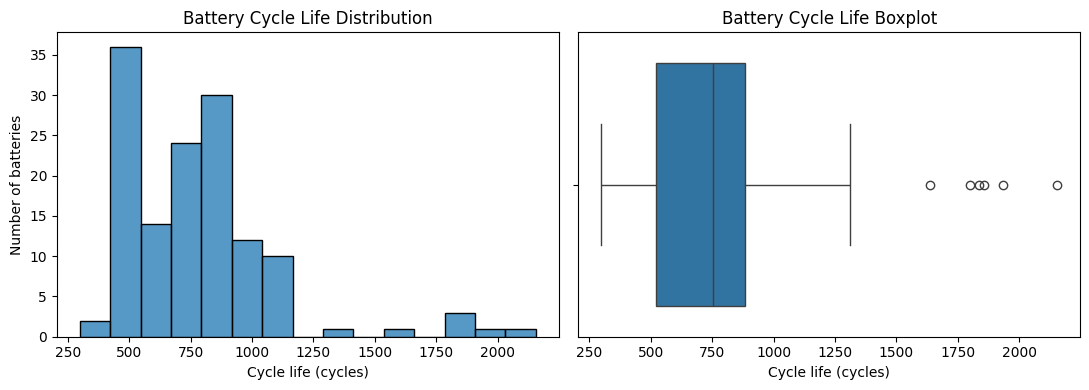

In [9]:
# Battery cycle life distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# left: histogram of cycle life
sns.histplot(
    data=train_df,
    x='cycle_life',
    bins=15,
    ax=axes[0]
)
axes[0].set_title('Battery Cycle Life Distribution')
axes[0].set_xlabel('Cycle life (cycles)')
axes[0].set_ylabel('Number of batteries')

# right: boxplot (box = middle 50%, points beyond the whiskers = 1.5 × IQR outliers)
sns.boxplot(
    data=train_df,
    x='cycle_life',
    ax=axes[1]
)
axes[1].set_title('Battery Cycle Life Boxplot')
axes[1].set_xlabel('Cycle life (cycles)')

plt.tight_layout()
plt.show()

Cycle life is **right-skewed**: most cells have short or medium lives and only a few live very long. Those few long-lived cells pull the mean upward and would dominate the model's errors. A **log10 transformation** compresses the long tail, makes the distribution more symmetric, and turns errors into relative errors. Models therefore predict **log10(cycle life)** (as in Severson et al., 2019).

Skewness of cycle life:       1.85
Skewness of log10 cycle life: 0.42


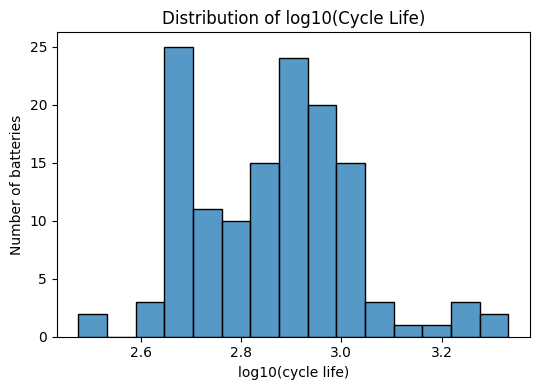

In [10]:
train_df['log_cycle_life'] = np.log10(train_df['cycle_life'])   #log-transformed target (EDA only)

# skewness near 0 = symmetric; positive = long right tail
print('Skewness of cycle life:      ', round(train_df['cycle_life'].skew(), 2))
print('Skewness of log10 cycle life:', round(train_df['log_cycle_life'].skew(), 2))

# histogram of the log-transformed target
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.histplot(data=train_df, x='log_cycle_life', bins=15, ax=ax)
ax.set_title('Distribution of log10(Cycle Life)')
ax.set_xlabel('log10(cycle life)')
ax.set_ylabel('Number of batteries')
plt.tight_layout()
plt.show()

### 5.4 Feature list
The 8 candidate features (all computed from cycles 1–100). `cell_id` (a name tag) and `cycle_life` (the target) are excluded.

In [11]:
# the 8 input features (used by the WITH-resistance models)
feature_cols = [
    'capacity_cycle_10_Ah',
    'capacity_cycle_100_Ah',
    'capacity_change_Ah',
    'capacity_slope_Ah_per_cycle',
    'mean_temperature_C',
    'max_temperature_C',
    'mean_resistance_ohm',
    'dQ_log_var'
]

### 5.5 Outliers (1.5 × IQR rule, Tukey's fences)
A value is flagged if it lies below Q1 − 1.5·IQR or above Q3 + 1.5·IQR, where IQR = Q3 − Q1. Outliers are **kept**: they reflect real cell behaviour (e.g. genuinely long-lived cells), not measurement errors. The upper fence of cycle life (1,419 cycles) is used later to define "long-lived" cells.

In [12]:
numeric_df = train_df[feature_cols + ['cycle_life']]   # features + target

q1 = numeric_df.quantile(0.25)   #25th percentile of each column
q3 = numeric_df.quantile(0.75)   #75th percentile of each column
iqr = q3 - q1                    #interquartile range

lower = q1 - 1.5 * iqr           #lower fence
upper = q3 + 1.5 * iqr           #upper fence

# True where a value lies outside the fences
outlier_flags = (
    numeric_df.lt(lower) | numeric_df.gt(upper)
)

outlier_summary = pd.DataFrame({
    'lower_bound': lower,
    'upper_bound': upper,
    'outlier_count': outlier_flags.sum()   #number of flagged batteries per column
})

display(outlier_summary)

,lower_bound,upper_bound,outlier_count
capacity_cycle_10_Ah,1.035320,1.103766,0
capacity_cycle_100_Ah,1.029843,1.105085,0
capacity_change_Ah,-0.004843,0.002954,13
capacity_slope_Ah_per_cycle,-0.000054,0.000026,17
mean_temperature_C,29.736676,36.461136,1
max_temperature_C,32.494140,41.907944,6
mean_resistance_ohm,-0.025280,0.042134,0
dQ_log_var,-5.030494,-2.791123,3
cycle_life,-13.000000,1419.000000,6


### 5.6 Feature relationships
Pearson correlation (r) of each feature with cycle life (−1 to +1; near 0 = no straight-line relationship), followed by the full correlation matrix to spot **redundant** features (pairs strongly correlated with each other, i.e. multicollinearity).

In [13]:
# correlation of every feature with cycle life
correlation = train_df[feature_cols + ['cycle_life']].corr()['cycle_life']
print(correlation.round(2))

capacity_cycle_10_Ah          -0.05
capacity_cycle_100_Ah          0.05
capacity_change_Ah             0.26
capacity_slope_Ah_per_cycle    0.28
mean_temperature_C             0.16
max_temperature_C             -0.14
mean_resistance_ohm           -0.02
dQ_log_var                    -0.81
cycle_life                     1.00
Name: cycle_life, dtype: float64


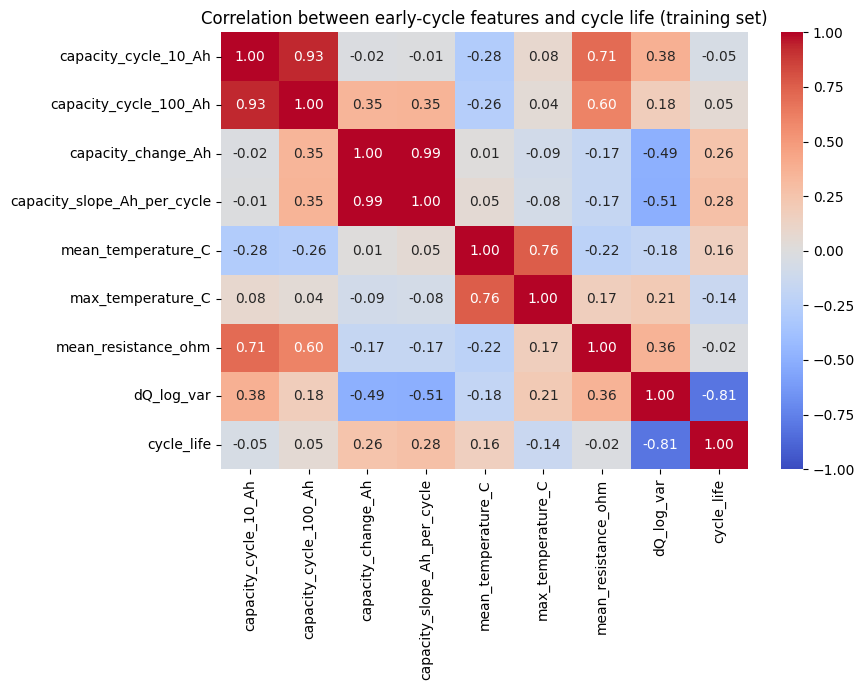

In [14]:
# heatmap of all pairwise correlations (red = positive, blue = negative, pale = weak)
plt.figure(figsize=(9, 7))
sns.heatmap(train_df[feature_cols + ['cycle_life']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between early-cycle features and cycle life (training set)')
plt.tight_layout()
plt.show()

## 6. Linear regression
Models are built from the EDA results above.

### 6.0 Shared cross-validation folds
All models are evaluated with the **same** 5-fold cross-validation (CV) splits of the training set: in each of 5 rounds a model is trained on 4/5 of the training cells and predicts the remaining 1/5, which it has not seen. The cells are shuffled before splitting, and `random_state=42` makes the folds identical for every model and every run.

In [15]:
#define fold
folds = KFold(n_splits = 5, shuffle =True, random_state = 42)   #5 folds, shuffled, reproducible

### 6.1 Linear regression WITH the resistance feature
Cells with resistance recorded as 0 Ω (missing) are removed from both the training and the test set.

In [16]:
#Step 1: remove the 0-ohm cells from the training and test sets
train_clean = train_df[train_df['mean_resistance_ohm'] != 0]
test_clean = test_df[test_df['mean_resistance_ohm'] != 0]

print('STEP 1: Remove cells with resistance = 0 ohm (missing data)')
print('Training cells before:', len(train_df), ' after:', len(train_clean))
print('Test cells before:', len(test_df), ' after:', len(test_clean))

STEP 1: Remove cells with resistance = 0 ohm (missing data)
Training cells before: 135  after: 97
Test cells before: 34  after: 27


In [17]:
# Step 2: inputs (8 feature columns)and target (y = log10 of cycle life)
X_train = train_clean[feature_cols]
X_test = test_clean[feature_cols]
y_train = np.log10(train_clean['cycle_life'])
y_test = np.log10(test_clean['cycle_life'])

print('\nSTEP 2: Inputs and target (rows = cells, columns = features)')
print('X_train shape:', X_train.shape)
print('X_test shape:', X_test.shape)
print('y_train shape:', y_train.shape)
print('y_test shape:', y_test.shape)


STEP 2: Inputs and target (rows = cells, columns = features)
X_train shape: (97, 8)
X_test shape: (27, 8)
y_train shape: (97,)
y_test shape: (27,)


In [18]:
#Step 3: train linear regression on the training cells only
lr = LinearRegression() # Initialize the Linear Regression model
lr.fit(X_train, y_train) #Train it --> fit it (training cells only; the test set stays unseen)

weights = pd.Series(lr.coef_, index=feature_cols)   # label each weight with its feature name

print('\nSTEP 3: Weight of each feature (target = log10 cycle life)--WITH Resistance)')
print(weights.round(4))
print('Intercept:', round(lr.intercept_, 4))


STEP 3: Weight of each feature (target = log10 cycle life)--WITH Resistance)
capacity_cycle_10_Ah             5.1606
capacity_cycle_100_Ah           -0.5710
capacity_change_Ah              -5.7316
capacity_slope_Ah_per_cycle    124.0983
mean_temperature_C               0.0607
max_temperature_C               -0.0336
mean_resistance_ohm              3.5926
dQ_log_var                      -0.3872
dtype: float64
Intercept: -4.3892


In [19]:
#Step 4: training error (cells the model has already seen -> optimistic)
y_train_pred = lr.predict(X_train) #predictions for the training sets (cells the model has already seen -> optimistic error)
pred_cycles = 10 ** y_train_pred #convert log10 predictions back to cycles
true_cycles = 10 ** y_train #true cycle life in cycles (used by all WITH-resistance models below)

#compute MAE and RMSE using true_cycles and pred_cycles (training error, in cycles)
mae = mean_absolute_error(true_cycles, pred_cycles) #Absolute Error
mse = mean_squared_error(true_cycles, pred_cycles) #Mean Squared Error
rmse = np.sqrt(mse) #Root Mean Squared Error

print('Linear Regression--MAE(WITH Resistance) result:', round(mae, 1))    # training MAE (cycles)
print('Linear Regression--RMSE(WITH Resistance) result:', round(rmse, 1))   # training RMSE (cycles)

Linear Regression--MAE(WITH Resistance) result: 76.9
Linear Regression--RMSE(WITH Resistance) result: 120.3


**5-fold cross-validation.** The training error above is optimistic, because the model is scored on cells it learned from.

In [20]:
#Step 5: 5-fold cross-validation (each cell predicted by a model that did not see it)
y_cv_pred = cross_val_predict(lr, X_train, y_train, cv=folds)
cv_pred_cycles = 10 ** y_cv_pred #back to cycles

cv_table = pd.DataFrame({
    'log10_prediction': y_cv_pred,
    'predicted_cycles': cv_pred_cycles,
})

print('Linear Regression(WITH Resistance) preview of the first 5-fold CV prediction')
print(cv_table.head(1))

cv_mae = mean_absolute_error(true_cycles, cv_pred_cycles)
cv_mse = mean_squared_error(true_cycles, cv_pred_cycles)
cv_rmse = np.sqrt(cv_mse)

print('\nLinear Regression--MAE(WITH Resistance) after 5-CV result:', round(cv_mae, 1)) #CV MAE (cycles)
print('Linear Regression--RMSE(WITH Resistance) result:', round(cv_rmse, 1)) #CV RMSE (cycles)

Linear Regression(WITH Resistance) preview of the first 5-fold CV prediction
   log10_prediction  predicted_cycles
0          2.730302        537.405278

Linear Regression--MAE(WITH Resistance) after 5-CV result: 95.7
Linear Regression--RMSE(WITH Resistance) result: 155.1


The dummy model ignores the features and always predicts the mean of the training folds. A useful model must beat it.

In [21]:
#Step 6:Dummy model: always predicts the training mean), same folds
dummy_regressor = DummyRegressor(strategy='mean')

dummy_pred = cross_val_predict(dummy_regressor, X_train, y_train, cv=folds)

dummy_pred_cycles = 10**dummy_pred

dummy_mae = mean_absolute_error(true_cycles, dummy_pred_cycles)
dummy_mse = mean_squared_error(true_cycles, dummy_pred_cycles)
dummy_rmse = np.sqrt(dummy_mse)

In [22]:
#Step 7: Final results
print('\nSTEP 4-7: Results (in cycles)')
print('First 5 CV predictions:')
print(cv_table.head(1).round(1))

lr_with_results = pd.DataFrame({
    'Evaluation': ['LR training error (optimistic)', 'LR 5-fold CV', 'Dummy 5-fold CV'],
    'MAE (cycles)':  [mae, cv_mae, dummy_mae],
    'RMSE (cycles)': [rmse, cv_rmse, dummy_rmse],
})
print(lr_with_results.round(1))


STEP 4-7: Results (in cycles)
First 5 CV predictions:
   log10_prediction  predicted_cycles
0               2.7             537.4
                       Evaluation  MAE (cycles)  RMSE (cycles)
0  LR training error (optimistic)          76.9          120.3
1                    LR 5-fold CV          95.7          155.1
2                 Dummy 5-fold CV         255.0          364.0


Linear regression WITH the resistance feature is done.

### 6.2 Linear regression WITHOUT the resistance feature
The resistance feature is dropped instead of the 0 Ω cells, so **all** training (135) and test (34) cells are kept, including batch 4. The same shared `folds` are used.

In [23]:
#Step 1: Remove one feature: the 7 features WIHTOUT mean_resistance_ohm
new_feature_cols = [
    'capacity_cycle_10_Ah',
    'capacity_cycle_100_Ah',
    'capacity_change_Ah',
    'capacity_slope_Ah_per_cycle',
    'mean_temperature_C',
    'max_temperature_C',
    'dQ_log_var'
]

In [24]:
# Repeat exactly what did before: Inputs (7 feature columns) and target (y = log10 of cycle life)
X_train_without = train_df[new_feature_cols]
X_test_without = test_df[new_feature_cols]
y_train_without = np.log10(train_df['cycle_life'])
y_test_without = np.log10(test_df['cycle_life'])

print('\nInputs and target (rows = cells, columns = features)')
print('X_train_without shape:', X_train_without.shape)
print('X_test_without shape:', X_test_without.shape)
print('y_train_without shape:', y_train_without.shape)
print('y_test_without shape:', y_test_without.shape)


Inputs and target (rows = cells, columns = features)
X_train_without shape: (135, 7)
X_test_without shape: (34, 7)
y_train_without shape: (135,)
y_test_without shape: (34,)


In [25]:
#Train linear regression on the training cells only
lr_without = LinearRegression() #Initialize a NEW Linear Regression model
lr_without.fit(X_train_without, y_train_without)

weights_without = pd.Series(lr_without.coef_, index=new_feature_cols)

print('\nSTEP 3: Weight of each feature (target = log10 cycle life)--WITHOUT-resistance')
print(weights_without.round(4))
print('Intercept:', round(lr_without.intercept_, 4))


STEP 3: Weight of each feature (target = log10 cycle life)--WITHOUT-resistance
capacity_cycle_10_Ah             6.7562
capacity_cycle_100_Ah           -1.9822
capacity_change_Ah              -8.7384
capacity_slope_Ah_per_cycle    494.4638
mean_temperature_C               0.0429
max_temperature_C               -0.0194
dQ_log_var                      -0.3947
dtype: float64
Intercept: -4.5017


In [26]:
#Same evaluation as did for the WITH Feature sections

y_train_pred_without = lr_without.predict(X_train_without)
pred_cycles_without = 10 ** y_train_pred_without
true_cycles_without = 10 ** y_train_without #true cycle life (used by all WITHOUT-resistance models below)

mae_without = mean_absolute_error(true_cycles_without, pred_cycles_without)
rmse_without = np.sqrt(mean_squared_error(true_cycles_without, pred_cycles_without))

#5-fold cross-validation (each cell predicted by a model that did not see it)
y_cv_pred_without = cross_val_predict(lr_without, X_train_without, y_train_without, cv=folds)
cv_pred_cycles_without = 10 ** y_cv_pred_without

cv_table_new = pd.DataFrame({
    'log10_prediction': y_cv_pred_without,
    'predicted_cycles': cv_pred_cycles_without,
})

cv_mae_new = mean_absolute_error(true_cycles_without, cv_pred_cycles_without)
cv_mse_new = mean_squared_error(true_cycles_without, cv_pred_cycles_without)
cv_rmse_new = np.sqrt(cv_mse_new)

#Dummy model
dummy_regressor_new = DummyRegressor(strategy='mean')
dummy_pred_new = cross_val_predict(dummy_regressor_new, X_train_without, y_train_without, cv=folds)
dummy_pred_cycles_new = 10 ** dummy_pred_new

dummy_mae_new = mean_absolute_error(true_cycles_without, dummy_pred_cycles_new)
dummy_mse_new = mean_squared_error(true_cycles_without, dummy_pred_cycles_new)
dummy_rmse_new = np.sqrt(dummy_mse_new)

#WITHOUT's esults
print('\nWITHOUT Resistance Results (in cycles)')
print('Linear regression (without resistance): first 5-fold CV prediction')
print(cv_table_new.head(1).round(1))

lr_without_results = pd.DataFrame({
    'Evaluation': ['LR training(without resistance) error', 'LR(without resistance) 5-fold CV', 'Dummy(without resistance) 5-fold CV'],
    'MAE--without resistance(cycles)':  [mae_without, cv_mae_new, dummy_mae_new],
    'RMSE--without resistance(cycles)': [rmse_without, cv_rmse_new, dummy_rmse_new],
})

print('\nLinear regression (without resistance): training vs. 5-fold CV vs. dummy')
print(lr_without_results.round(1))


WITHOUT Resistance Results (in cycles)
Linear regression (without resistance): first 5-fold CV prediction
   log10_prediction  predicted_cycles
0               2.7             524.5

Linear regression (without resistance): training vs. 5-fold CV vs. dummy
                              Evaluation  MAE--without resistance(cycles)  \
0  LR training(without resistance) error                             81.4   
1       LR(without resistance) 5-fold CV                             87.6   
2    Dummy(without resistance) 5-fold CV                            222.0   

   RMSE--without resistance(cycles)  
0                             125.7  
1                             134.3  
2                             318.9  


Linear regression is done for both versions.

## 7. Random forest
A random forest averages many decision trees, so it can capture **nonlinear** relationships and interactions that the weak straight-line correlations in the EDA may have missed. Hyperparameters are tuned with `GridSearchCV` on the shared 5 folds (training set only).

### 7.1 Random forest WITH the resistance feature

In [27]:
random_state = 42
long_battery_life = 1419   # upper 1.5*IQR fence of cycle life (EDA) Used to investigate prediction accuracy of long-life cell

# keep resistance, drop the 0-ohm cells (same data as the LR baseline)
rf_features = feature_cols
rf_train = train_df[train_df['mean_resistance_ohm'] != 0]
rf_test = test_df[test_df['mean_resistance_ohm'] != 0]

X_train_rf = rf_train[rf_features]
y_train_rf = np.log10(rf_train['cycle_life'])
X_test_rf = rf_test[rf_features]
y_test_rf = np.log10(rf_test['cycle_life'])
print("train dataset size:", X_train_rf.shape, "\ntest dataset size:", X_test_rf.shape)

train dataset size: (97, 8) 
test dataset size: (27, 8)


In [28]:
# Apply cross-validation on training set only
# settings to try (4 x 4 x 3 = 48 combinations, each scored with 5-fold CV)
param_grid_rf = {
    'max_depth':        [None, 3, 5, 8],       # maximum depth of each tree (None = unlimited)
    'min_samples_leaf': [1, 3, 5, 10],         # minimum number of cells in a leaf
    'max_features':     [1.0, 0.5, 'sqrt'],    # share of features considered at each split
}
rf = RandomForestRegressor(n_estimators=300, random_state=random_state, n_jobs=-1)   # 300 trees
grid = GridSearchCV(rf, param_grid_rf, cv=folds, scoring='neg_mean_absolute_error', n_jobs=-1)
grid.fit(X_train_rf, y_train_rf)

rf_best = grid.best_estimator_   # forest with the best settings, refit on all training cells
print('Best parameters:', grid.best_params_)

Best parameters: {'max_depth': 5, 'max_features': 1.0, 'min_samples_leaf': 1}


In [29]:
# 5-fold CV predictions of the tuned forest
y_cv_rf = cross_val_predict(rf_best, X_train_rf, y_train_rf, cv=folds)

true_cycles_rf = 10 ** y_train_rf   # back to cycles
cv_pred_cycles_rf = 10 ** y_cv_rf

rf_cv_mae = mean_absolute_error(true_cycles_rf, cv_pred_cycles_rf)
rf_cv_rmse = np.sqrt(mean_squared_error(true_cycles_rf, cv_pred_cycles_rf))
print(f'RF Cross Validation reuslts:\n MAE = {rf_cv_mae:.1f} cycles,\n RMSE = {rf_cv_rmse:.1f} cycles')

RF Cross Validation reuslts:
 MAE = 89.3 cycles,
 RMSE = 145.5 cycles


In [30]:
# Investigate prediction accuracy on long-life cell
long_life_cell = true_cycles_rf > long_battery_life   # True for cells above the 1,419-cycle fence
err = cv_pred_cycles_rf - true_cycles_rf              # signed error: positive = predicted too long

summary = pd.DataFrame({
    'Number of cells': [long_life_cell.sum(), (~long_life_cell).sum()],
    'MAE (cycles)': [err[long_life_cell].abs().mean(), err[~long_life_cell].abs().mean()],
    #'mean signed error (pred - true)': [err[long_life_cell].mean(), err[~long_life_cell].mean()],
}, index=['Long-lived (> 1419)', 'Typical (<= 1419)'])
display(summary.round(1))

,Number of cells,MAE (cycles)
Long-lived (> 1419),6,326.0
Typical (<= 1419),91,73.7


**Permutation importance.** For each fold, one feature at a time is randomly shuffled in the validation cells and the increase in validation error is recorded. A large increase means the model relies on that feature. Bars show the mean over the 5 folds, and error bars the standard deviation.

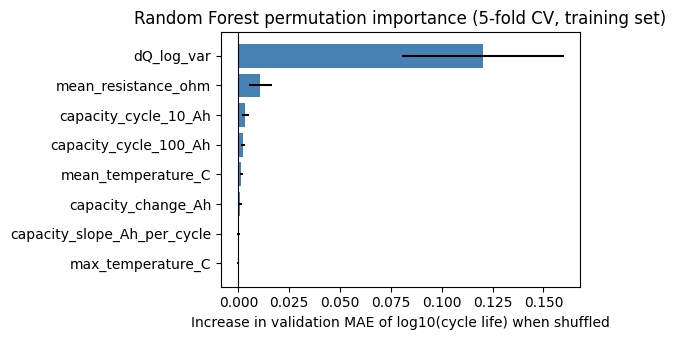

max_temperature_C             -0.0001
capacity_slope_Ah_per_cycle    0.0002
capacity_change_Ah             0.0006
mean_temperature_C             0.0015
capacity_cycle_100_Ah          0.0022
capacity_cycle_10_Ah           0.0035
mean_resistance_ohm            0.0108
dQ_log_var                     0.1202
dtype: float64


In [31]:
# Determine the most related early feature
fold_imps = []   # importance values of each fold
for tr_idx, va_idx in folds.split(X_train_rf):
    model = clone(rf_best).fit(X_train_rf.iloc[tr_idx], y_train_rf.iloc[tr_idx])   # fresh forest, trained on 4 folds
    result = permutation_importance(model, X_train_rf.iloc[va_idx], y_train_rf.iloc[va_idx],scoring='neg_mean_absolute_error',
                                    n_repeats=20, random_state=random_state)       # shuffle each feature 20 times
    fold_imps.append(result.importances_mean)

fold_imps = pd.DataFrame(fold_imps, columns=rf_features)   # rows = folds, columns = features
imp = fold_imps.mean().sort_values()                        # mean importance, sorted
imp_sd = fold_imps.std()[imp.index]                         # spread across folds

# horizontal bar chart with error bars
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(imp.index, imp.values, xerr=imp_sd.values, color='steelblue')
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('Increase in validation MAE of log10(cycle life) when shuffled')
ax.set_title('Random Forest permutation importance (5-fold CV, training set)')
plt.tight_layout()
plt.show()
print(imp.round(4))

### 7.2 Random forest WITHOUT the resistance feature
Same settings grid and folds, using all 135 training cells and 7 features.

In [32]:
# Random Forest WITHOUT the resistance feature (all 135 training cells)
param_grid_rf_without = {
    'max_depth':        [None, 3, 5, 8],
    'min_samples_leaf': [1, 3, 5, 10],
    'max_features':     [1.0, 0.5, 'sqrt'],
}
rf_without = RandomForestRegressor(n_estimators=300, random_state=random_state, n_jobs=-1)
grid_without = GridSearchCV(rf_without, param_grid_rf_without, cv=folds, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_without.fit(X_train_without, y_train_without)

rf_best_without = grid_without.best_estimator_   # tuned forest (7 features)
print('Best parameters (RF without resistance):', grid_without.best_params_)

Best parameters (RF without resistance): {'max_depth': 5, 'max_features': 1.0, 'min_samples_leaf': 1}


In [33]:
# 5-fold CV predictions of the tuned forest (without resistance)
y_cv_rf_without = cross_val_predict(rf_best_without, X_train_without, y_train_without, cv=folds)

true_cycles_rf_without = 10 ** y_train_without
cv_pred_cycles_rf_without = 10 ** y_cv_rf_without

# "_7" = the 7-feature version (without resistance)
rf_cv_mae_7 = mean_absolute_error(true_cycles_rf_without, cv_pred_cycles_rf_without)
rf_cv_rmse_7 = np.sqrt(mean_squared_error(true_cycles_rf_without, cv_pred_cycles_rf_without))
print(f'RF Cross Validation Results (without resistance):\n MAE = {rf_cv_mae_7:.1f} cycles,\n RMSE = {rf_cv_rmse_7:.1f} cycles')

RF Cross Validation Results (without resistance):
 MAE = 99.5 cycles,
 RMSE = 157.3 cycles


In [34]:
# Prediction accuracy on long-lived cells
long_life_cell_7 = true_cycles_rf_without > long_battery_life
err_7 = cv_pred_cycles_rf_without - true_cycles_rf_without   # positive = predicted too long

summary_7 = pd.DataFrame({
    'Number of cells': [long_life_cell_7.sum(), (~long_life_cell_7).sum()],
    'MAE (cycles)': [err_7[long_life_cell_7].abs().mean(), err_7[~long_life_cell_7].abs().mean()],
}, index=['Long-lived (> 1419)', 'Typical (<= 1419)'])
display(summary_7.round(1))

,Number of cells,MAE (cycles)
Long-lived (> 1419),6,426.6
Typical (<= 1419),129,84.3


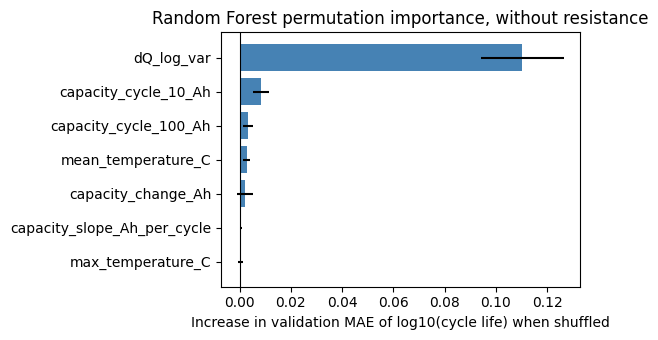

max_temperature_C              0.0005
capacity_slope_Ah_per_cycle    0.0005
capacity_change_Ah             0.0023
mean_temperature_C             0.0029
capacity_cycle_100_Ah          0.0033
capacity_cycle_10_Ah           0.0085
dQ_log_var                     0.1103
dtype: float64


In [35]:
# Permutation importance: Random Forest WITHOUT resistance (135 cells, 7 features)
fold_imps_7 = []
for tr_idx, va_idx in folds.split(X_train_without):
    model = clone(rf_best_without).fit(X_train_without.iloc[tr_idx], y_train_without.iloc[tr_idx])
    result = permutation_importance(model, X_train_without.iloc[va_idx], y_train_without.iloc[va_idx],
                                    scoring='neg_mean_absolute_error',
                                    n_repeats=20, random_state=random_state)
    fold_imps_7.append(result.importances_mean)

fold_imps_7 = pd.DataFrame(fold_imps_7, columns=new_feature_cols)
imp_7 = fold_imps_7.mean().sort_values()
imp_sd_7 = fold_imps_7.std()[imp_7.index]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(imp_7.index, imp_7.values, xerr=imp_sd_7.values, color='steelblue')
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('Increase in validation MAE of log10(cycle life) when shuffled')
ax.set_title('Random Forest permutation importance, without resistance')
plt.tight_layout()
plt.show()
print(imp_7.round(4))

## 8. Elastic net
Elastic net is linear regression with a **penalty on the size of the weights**, which stabilizes the coefficients of correlated (redundant) features found in the EDA:
- **L2 (ridge) part** shrinks all weights and shares weight between correlated features
- **L1 (lasso) part** can set unhelpful weights to exactly 0

Two hyperparameters are tuned: `alpha` (penalty strength) and `l1_ratio` (mix of L1 and L2). Features are standardized first, so the penalty treats them fairly. Scaler and model are combined in a **pipeline**, so the scaling is learned from the training folds only in every CV round (no leakage).

### 8.1 Elastic net WITH the resistance feature
**Default settings first** (`alpha = 1`):

In [36]:
#Step 1: Elastic Net with DEFAULT settings (alpha = 1)
# pipeline: standardize features, then elastic net (max_iter raised so the solver converges
model_with = make_pipeline(StandardScaler(), ElasticNet(max_iter=10000))

predictions_with = cross_val_predict(model_with, X_train, y_train, cv=folds)
pred_cycles_with = 10 ** predictions_with

mae_net = mean_absolute_error(true_cycles, pred_cycles_with)
mse_net = mean_squared_error(true_cycles, pred_cycles_with)
rmse_net = np.sqrt(mse_net)

print('STEP 1: Elastic net with default settings (alpha = 1)')
print('CV MAE(WITH)--Elastic Net(cycles):', round(mae_net, 1))
print('CV RMSE (WITH)--Elastic Net(cycles):', round(rmse_net, 1))
print('First 5 predictions WITH Resistance for Elastic Net(cycles):', pred_cycles_with[:5].round(1))

STEP 1: Elastic net with default settings (alpha = 1)
CV MAE(WITH)--Elastic Net(cycles): 255.0
CV RMSE (WITH)--Elastic Net(cycles): 364.0
First 5 predictions WITH Resistance for Elastic Net(cycles): [715.8 704.8 704.8 730.9 715.8]


With the default settings the result is **exactly the same as the dummy model**, and every cell gets the same prediction. The default penalty (`alpha = 1`) is too strong for this target (log10 cycle life varies by only about ±0.15), so all weights are pushed to 0 and the model predicts the mean. The hyperparameters therefore need **tuning**.

**Tuning with `GridSearchCV`.** Every combination of `alpha` and `l1_ratio` is scored with the shared 5-fold CV on the training set, and the combination with the lowest MAE is kept. Inside a pipeline, a setting is named `<step name>__<setting>`, e.g. `elasticnet__alpha`.

In [37]:
#Step 2: Tuning -- Alpha (penalty strength) & L1_ratio (L1/L2 mix) with 5-fold CV
param_grid_en = {
    'elasticnet__alpha': [0.001, 0.01, 0.1, 1],  #penalty strength
    'elasticnet__l1_ratio': [0.1, 0.2, 0.4, 0.6, 0.8, 1.0], #0 = pure ridge (L2), 1 = pure lasso (L1)
}

search_with = GridSearchCV(model_with, param_grid_en, cv=folds, scoring='neg_mean_absolute_error')
search_with.fit(X_train, y_train) #tries all 24 combinations, then refits the best on all training cells

print('\nSTEP 2: Tuning results')
print('Best settings(WITH)--Elastic Net:', search_with.best_params_)#best alpha and l1_ratio
print('Best CV MAE(WITH)--Elastic Net (log10 units):', round(-search_with.best_score_, 3)) #best CV score = negative MAE in log10 units


STEP 2: Tuning results
Best settings(WITH)--Elastic Net: {'elasticnet__alpha': 0.01, 'elasticnet__l1_ratio': 0.2}
Best CV MAE(WITH)--Elastic Net (log10 units): 0.045


In [38]:
# Step 3: Evaluation; 5-fold CV predictions of the tuned elastic net
cv_pred_netwith = cross_val_predict(search_with.best_estimator_, X_train, y_train, cv=folds)

cv_pred_cycles_netwith= 10**cv_pred_netwith

cv_table_netwith = pd.DataFrame({
    'log10_prediction': cv_pred_netwith,
    'predicted_cycles': cv_pred_cycles_netwith,
})

print('Elastic net (with resistance): first 5-fold CV prediction')
print(cv_table_netwith.head(1).round(1))

Elastic net (with resistance): first 5-fold CV prediction
   log10_prediction  predicted_cycles
0               2.7             500.5


In [39]:
#now computing cv MAE and RMSE
mae_netwith = mean_absolute_error(true_cycles, cv_pred_cycles_netwith)
mse_netwith= mean_squared_error(true_cycles, cv_pred_cycles_netwith)
rmse_netwith = np.sqrt(mse_netwith)

print('Tuned elastic net CV MAE (cycles):', round(mae_netwith, 1))
print('Tuned elastic net CV RMSE (cycles):', round(rmse_netwith, 1))

#quick comparing with dummy model
dummy_regressor_netwith= DummyRegressor(strategy='mean')

dummy_pred_netwith = cross_val_predict(dummy_regressor_netwith, X_train, y_train, cv=folds)

dummy_pred_cycles_netwith = 10**dummy_pred_netwith

dummy_mae_netwith= mean_absolute_error(true_cycles, dummy_pred_cycles_netwith)
dummy_mse_netwith = mean_squared_error(true_cycles, dummy_pred_cycles_netwith)
dummy_rmse_netwith = np.sqrt(dummy_mse_netwith)

print('Dummy(with resistance): CV MAE (cycles):', round(dummy_mae_netwith, 1))
print('Dummy(with resistance): CV RMSE (cycles):', round(dummy_rmse_netwith, 1))

Tuned elastic net CV MAE (cycles): 88.5
Tuned elastic net CV RMSE (cycles): 144.2
Dummy(with resistance): CV MAE (cycles): 255.0
Dummy(with resistance): CV RMSE (cycles): 364.0


In [40]:
# results table (WITH resistance): dummy vs linear regression vs tuned elastic net
Net_with_results = pd.DataFrame ({
    'model': ['Dummy', 'Linear Regression(WITH)', 'ElasticNet_WITH(tuned)'],
    'CV_MAE':  [dummy_mae_netwith, cv_mae, mae_netwith],
    'CV_RMSE': [dummy_rmse_netwith, cv_rmse, rmse_netwith],
})

Net_with_results['improvement(%)'] = ((dummy_mae_netwith-Net_with_results['CV_MAE']) / dummy_mae_netwith )* 100

print(Net_with_results.round(1))

                     model  CV_MAE  CV_RMSE  improvement(%)
0                    Dummy   255.0    364.0             0.0
1  Linear Regression(WITH)    95.7    155.1            62.5
2   ElasticNet_WITH(tuned)    88.5    144.2            65.3


**Tuned weights.** Because the features were standardized, the weights can be compared: a larger absolute weight means a larger effect on predicted log10(cycle life). A weight of exactly 0 means the L1 part removed that feature.

In [41]:
#Step 4: reading the tuned weights: take the elastic net step out of the tuned pipeline

best_ENet_with = search_with.best_estimator_.named_steps['elasticnet']

print(best_ENet_with) #shows the chosen alpha and l1_ratio

# label the weights with the feature names
ENet_weights_with = pd.Series(best_ENet_with.coef_, index = X_train.columns)

print('\nTuned elastic net:', best_ENet_with)
print('\nWeight of each feature (larger size = larger effect; 0 = removed by L1)--WITH-resistance:')
print(ENet_weights_with.round(4))

ElasticNet(alpha=0.01, l1_ratio=0.2, max_iter=10000)

Tuned elastic net: ElasticNet(alpha=0.01, l1_ratio=0.2, max_iter=10000)

Weight of each feature (larger size = larger effect; 0 = removed by L1)--WITH-resistance:
capacity_cycle_10_Ah           0.0366
capacity_cycle_100_Ah          0.0000
capacity_change_Ah            -0.0159
capacity_slope_Ah_per_cycle   -0.0000
mean_temperature_C             0.0489
max_temperature_C             -0.0380
mean_resistance_ohm           -0.0097
dQ_log_var                    -0.1478
dtype: float64


### 8.2 Long-lived cells
The TA asked how well the model predicts the unusually long-lived cells (kept as genuine behaviour in the EDA). Cells above the 1,419-cycle fence are compared with all other cells.

In [42]:
#Step 5: Long-lived Test
#let's try predict the long-lived one: table of true vs CV-predicted life per cell

cells_with = pd.DataFrame({
    'true_cycles': true_cycles,
    'pred_cycles': cv_pred_cycles_netwith,

})

#signed error: positive = predicted too long, negative = predicted too short
cells_with['error'] = cells_with['pred_cycles'] - cells_with['true_cycles']

#True for long-lived cells (above the 1,419-cycle fence from the EDA)
cells_with['long_lived'] = cells_with['true_cycles'] > 1419

print('Elastic net (with resistance): true vs. CV-predicted cycle life (first cell)')
print(cells_with.head(1).round(1))
print('\nNumber of long-lived cells (> 1419 cycles):', cells_with['long_lived'].sum())

Elastic net (with resistance): true vs. CV-predicted cycle life (first cell)
    true_cycles  pred_cycles  error  long_lived
69        534.0        500.5  -33.5       False

Number of long-lived cells (> 1419 cycles): 6


In [43]:
# split the table into the two groups
long = cells_with[cells_with['long_lived'] == True]
normal = cells_with[cells_with['long_lived'] == False]

print('Long-lived cells (> 1419 cycles):', len(long), '  other cells:', len(normal))
print('\nLong-lived cells: true vs. CV-predicted cycle life(WITH-Resistance)')
print(long.round(1))

print('MAE of long-lived cells (cycles):', round(long['error'].abs().mean(), 1))
print('MAE of all other cells (cycles):', round(normal['error'].abs().mean(), 1))

Long-lived cells (> 1419 cycles): 6   other cells: 91

Long-lived cells: true vs. CV-predicted cycle life(WITH-Resistance)
     true_cycles  pred_cycles  error  long_lived
0         1858.0       2380.5  522.5        True
118       1799.0       1358.8 -440.2        True
112       1932.0       1189.4 -742.6        True
1         2154.0       2481.8  327.8        True
121       1834.0       1350.0 -484.0        True
92        1635.0       1537.9  -97.1        True
MAE of long-lived cells (cycles): 435.7
MAE of all other cells (cycles): 65.7


### 8.3 Fold-to-fold uncertainty
With a small dataset, the error depends on which cells end up in each fold. The MAE of each of the 5 folds shows how stable the result is.

In [44]:
# Check each fold in CV --> stability of the results
# MAE for each fold (cycles) -- WITH resistance
fold_maes = []

print('MAE per fold (cycles) -- WITH resistance')
for i, (learn_idx, check_idx) in enumerate(folds.split(X_train), start=1):
    fold_cells = cells_with.iloc[check_idx]  # cells predicted in this fold
    mae = fold_cells['error'].abs().mean()
    fold_maes.append(mae)
    print(f'Fold {i}: {mae:6.1f}')

print(f'Mean:   {np.mean(fold_maes):6.1f}')
print(f'Std:    {np.std(fold_maes):6.1f}')
print(f'Range:  {min(fold_maes):.1f} – {max(fold_maes):.1f}')

MAE per fold (cycles) -- WITH resistance
Fold 1:   88.0
Fold 2:   91.5
Fold 3:   68.4
Fold 4:   96.1
Fold 5:   98.6
Mean:     88.5
Std:      10.7
Range:  68.4 – 98.6


### 8.4 Elastic net WITHOUT the resistance feature
Same pipeline, settings grid and folds, using all 135 training cells and 7 features.

In [45]:
# Elastic Net WITHOUT the resistance feature (all 135 training cells)
model_without = make_pipeline(StandardScaler(), ElasticNet(max_iter=10000))
param_grid_en_without = {
    'elasticnet__alpha': [0.001, 0.01, 0.1, 1],
    'elasticnet__l1_ratio': [0.1, 0.2, 0.4, 0.6, 0.8, 1.0],
}
search_without = GridSearchCV(model_without, param_grid_en_without, cv=folds, scoring='neg_mean_absolute_error')
search_without.fit(X_train_without, y_train_without)
print('Best parameters (without resistance):', search_without.best_params_)


Best parameters (without resistance): {'elasticnet__alpha': 0.001, 'elasticnet__l1_ratio': 0.2}


In [46]:
# 5-fold CV predictions of the tuned model, in cycles
cv_pred_netwithout = cross_val_predict(search_without.best_estimator_, X_train_without, y_train_without, cv=folds)
cv_pred_cycles_netwithout = 10 ** cv_pred_netwithout

mae_netwithout = mean_absolute_error(true_cycles_without, cv_pred_cycles_netwithout)
rmse_netwithout = np.sqrt(mean_squared_error(true_cycles_without, cv_pred_cycles_netwithout))
print(f'Elastic Net Cross Validation Results (WITHOUT resistance) ({len(X_train_without)} cells): '
      f'MAE = {mae_netwithout:.1f}, RMSE = {rmse_netwithout:.1f}')

Elastic Net Cross Validation Results (WITHOUT resistance) (135 cells): MAE = 87.1, RMSE = 134.2


In [47]:
# tuned weights (standardized features, so they can be compared)
ENet_weights_without = pd.Series(search_without.best_estimator_.named_steps['elasticnet'].coef_,
                                 index=new_feature_cols)
print(ENet_weights_without.round(4))

capacity_cycle_10_Ah           0.0616
capacity_cycle_100_Ah          0.0000
capacity_change_Ah            -0.0257
capacity_slope_Ah_per_cycle    0.0000
mean_temperature_C             0.0564
max_temperature_C             -0.0396
dQ_log_var                    -0.1510
dtype: float64


In [48]:
# Long-lived cells: Elastic Net WITHOUT resistance (135 training cells)
cells_without = pd.DataFrame({
    'true_cycles': true_cycles_without,
    'pred_cycles': cv_pred_cycles_netwithout,
})

# signed error: positive = predicted too long, negative = predicted too short
cells_without['error'] = cells_without['pred_cycles'] - cells_without['true_cycles']
cells_without['long_lived'] = cells_without['true_cycles'] > long_battery_life   # 1419 cycles

long_7 = cells_without[cells_without['long_lived']]
normal_7 = cells_without[~cells_without['long_lived']]

print('Long-lived cells (> 1419 cycles):', len(long_7), '  other cells:', len(normal_7))
print('\nLong-lived cells: true vs. CV-predicted cycle life (WITHOUT resistance)')
print(long_7.round(1))
print('MAE of long-lived cells (cycles):', round(long_7['error'].abs().mean(), 1))
print('MAE of all other cells (cycles):', round(normal_7['error'].abs().mean(), 1))

Long-lived cells (> 1419 cycles): 6   other cells: 129

Long-lived cells: true vs. CV-predicted cycle life (WITHOUT resistance)
     true_cycles  pred_cycles  error  long_lived
0         1858.0       2265.8  407.8        True
118       1799.0       1301.8 -497.2        True
112       1932.0       1189.9 -742.1        True
1         2154.0       2154.0    0.0        True
121       1834.0       1298.1 -535.9        True
92        1635.0       1538.1  -96.9        True
MAE of long-lived cells (cycles): 380.0
MAE of all other cells (cycles): 73.5


**Fair comparison of the two versions.** The two versions are trained on different cells (97 vs 135), so their raw MAEs are not directly comparable. Here the WITHOUT-resistance predictions are also scored on the same 97 cells used by the WITH-resistance version.

In [49]:
# Fair comparison: score both versions on the same 97 cells that have valid resistance
common_cells = X_train.index   # row labels of the 97 cells with valid resistance
without_pred = pd.Series(cv_pred_cycles_netwithout, index=X_train_without.index).loc[common_cells]
without_true = true_cycles_without.loc[common_cells]

print(f'Elastic Net WITHOUT resistance (trained on 135), scored on the same 97 cells: '
      f'MAE = {mean_absolute_error(without_true, without_pred):.1f}, '
      f'RMSE = {np.sqrt(mean_squared_error(without_true, without_pred)):.1f}')
print(f'Elastic Net WITH resistance (trained on 97):                                 '
      f'MAE = {mae_netwith:.1f}, RMSE = {rmse_netwith:.1f}')

Elastic Net WITHOUT resistance (trained on 135), scored on the same 97 cells: MAE = 81.0, RMSE = 137.8
Elastic Net WITH resistance (trained on 97):                                 MAE = 88.5, RMSE = 144.2


## 9. Model comparison
### 9.1 Predicted vs. true cycle life
Each point is one training cell, predicted by 5-fold CV. Points on the dashed line are perfect predictions; red diamonds are the long-lived cells (> 1,419 cycles).

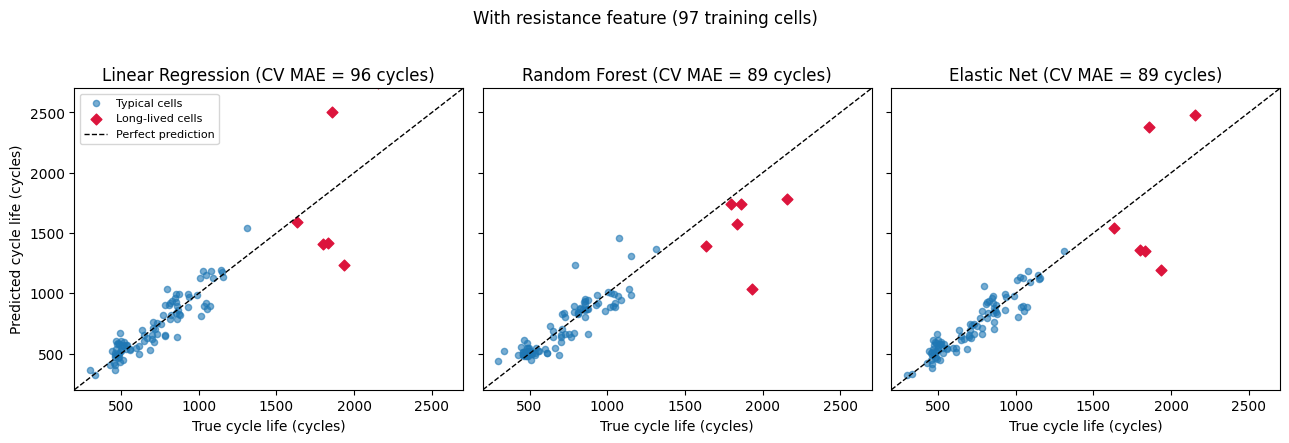

In [50]:
# Predicted vs actual (5-fold CV, training set), three models with resistance
cv_preds = {
    'Linear Regression': cv_pred_cycles,
    'Random Forest':     cv_pred_cycles_rf,
    'Elastic Net':       cv_pred_cycles_netwith,
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), sharex=True, sharey=True)   # one panel per model
lims = [200, 2700]   # axis range (cycles)
for ax, (name, pred) in zip(axes, cv_preds.items()):
    pred = np.asarray(pred)
    true = np.asarray(true_cycles)
    long = true > long_battery_life   # mask of long-lived cells
    ax.scatter(true[~long], pred[~long], alpha=0.6, s=20, label='Typical cells')
    ax.scatter(true[long], pred[long], color='crimson', marker='D', s=30, label='Long-lived cells')
    ax.plot(lims, lims, 'k--', lw=1, label='Perfect prediction')   # y = x line
    mae = mean_absolute_error(true, pred)
    ax.set_title(f'{name} (CV MAE = {mae:.0f} cycles)')
    ax.set_xlabel('True cycle life (cycles)')
    ax.set_xlim(lims); ax.set_ylim(lims)
axes[0].set_ylabel('Predicted cycle life (cycles)')
axes[0].legend(fontsize=8)
fig.suptitle('With resistance feature (97 training cells)', y=1.02)
plt.tight_layout()
plt.show()

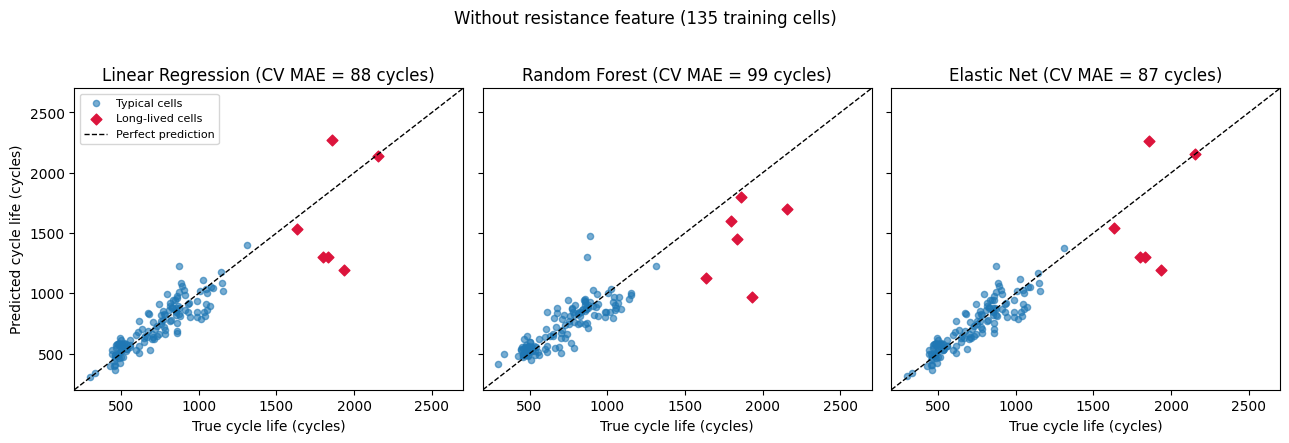

In [51]:
# Predicted vs actual (5-fold CV, training set), three models without resistance
cv_preds_without = {
    'Linear Regression': cv_pred_cycles_without,
    'Random Forest':     cv_pred_cycles_rf_without,
    'Elastic Net':       cv_pred_cycles_netwithout,
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), sharex=True, sharey=True)   # one panel per model
lims = [200, 2700]   # axis range (cycles)
for ax, (name, pred) in zip(axes, cv_preds_without.items()):
    pred = np.asarray(pred)
    true = np.asarray(true_cycles_without)
    long = true > long_battery_life        # mask of long-lived cells
    ax.scatter(true[~long], pred[~long], alpha=0.6, s=20, label='Typical cells')
    ax.scatter(true[long], pred[long], color='crimson', marker='D', s=30, label='Long-lived cells')
    ax.plot(lims, lims, 'k--', lw=1, label='Perfect prediction')   # y = x line
    mae = mean_absolute_error(true, pred)
    ax.set_title(f'{name} (CV MAE = {mae:.0f} cycles)')
    ax.set_xlabel('True cycle life (cycles)')
    ax.set_xlim(lims); ax.set_ylim(lims)
axes[0].set_ylabel('Predicted cycle life (cycles)')
axes[0].legend(fontsize=8)
fig.suptitle('Without resistance feature (135 training cells)', y=1.02)
plt.tight_layout()
plt.show()

### 9.2 Summary table
Every model in both versions, evaluated with the same 5-fold CV: MAE, RMSE, MAPE, and the MAE on long-lived cells. The table is also saved to `eda_outputs/model_comparison.csv`.

In [52]:
# Summary table built from the CV predictions already computed above (no re-training)
cv_results = {
    # (model, resistance feature): (true cycles, CV-predicted cycles)
    ('Dummy (mean)',      'with'):    (true_cycles,            dummy_pred_cycles),
    ('Dummy (mean)',      'without'): (true_cycles_without,    dummy_pred_cycles_new),
    ('Linear Regression', 'with'):    (true_cycles,            cv_pred_cycles),
    ('Linear Regression', 'without'): (true_cycles_without,    cv_pred_cycles_without),
    ('Random Forest',     'with'):    (true_cycles_rf,         cv_pred_cycles_rf),
    ('Random Forest',     'without'): (true_cycles_rf_without, cv_pred_cycles_rf_without),
    ('Elastic Net',       'with'):    (true_cycles,            cv_pred_cycles_netwith),
    ('Elastic Net',       'without'): (true_cycles_without,    cv_pred_cycles_netwithout),
}

summary_rows = []
for (model_name, version), (true_c, pred_c) in cv_results.items():
    true_c, pred_c = np.asarray(true_c), np.asarray(pred_c)
    is_long = true_c > long_battery_life
    summary_rows.append({
        'Model': model_name,
        'Resistance feature': version,
        'Training cells': len(true_c),
        'CV MAE': mean_absolute_error(true_c, pred_c),
        'CV RMSE': np.sqrt(mean_squared_error(true_c, pred_c)),
        'CV MAPE (%)': mean_absolute_percentage_error(true_c, pred_c) * 100,
        'MAE, long-lived cells': mean_absolute_error(true_c[is_long], pred_c[is_long]),
    })

summary_table = pd.DataFrame(summary_rows).set_index(['Model', 'Resistance feature'])
display(summary_table.round(1))

Training cells  CV MAE  CV RMSE  \
Model             Resistance feature                                    
Dummy (mean)      with                            97   255.0    364.0   
                  without                        135   222.0    318.9   
Linear Regression with                            97    95.7    155.1   
                  without                        135    87.6    134.3   
Random Forest     with                            97    89.3    145.5   
                  without                        135    99.5    157.3   
Elastic Net       with                            97    88.5    144.2   
                  without                        135    87.1    134.2   

                                      CV MAPE (%)  MAE, long-lived cells  
Model             Resistance feature                                      
Dummy (mean)      with                       33.0                 1150.9  
                  without                    29.3                 1144.1  
Linear Regression with                       11.1                  464.5  
                  without                    10.6                  382.2  
Random Forest     with                       11.1                  326.0  
                  without                    12.3                  426.6  
Elastic Net       with                       10.4                  435.7  
                  without                    10.6                  380.0

The "with-resistance" and "without-resistance" results can not be compared directly.

Since 38 training cells report a physically impossible resistance of 0 Ω, models that use the resistance feature can only be trained and evaluated on the remaining 97 cells, whereas models without this feature use all 135 training cells.

To isolate the effect of the feature, both versions were scored on the same 97 cells that have valid resistance values. The without-resistance models were still trained on all 135 cells, but their predictions were evaluated only on these 97 cells. Within each feature set, the three models share the same cells and the same cross-validation folds, so they can be compared directly.

In [53]:
cv_results_97 = {
    # (model, resistance feature): (true cycles, CV-predicted cycles)
    ('Dummy (mean)',      'with'):    (true_cycles,            dummy_pred_cycles),
    ('Dummy (mean)',      'without'): (true_cycles_without,    dummy_pred_cycles_new),
    ('Linear Regression', 'with'):    (true_cycles,            cv_pred_cycles),
    ('Linear Regression', 'without'): (true_cycles_without,    cv_pred_cycles_without),
    ('Random Forest',     'with'):    (true_cycles_rf,         cv_pred_cycles_rf),
    ('Random Forest',     'without'): (true_cycles_rf_without, cv_pred_cycles_rf_without),
    ('Elastic Net',       'with'):    (true_cycles,            cv_pred_cycles_netwith),
    ('Elastic Net',       'without'): (true_cycles_without,    cv_pred_cycles_netwithout),
}
common_cells = X_train.index   # the 97 cells with valid resistance

summary_rows_97 = []
for (model_name, version), (true_c, pred_c) in cv_results_97.items():
    idx = true_c.index                                          # cell IDs, to find the 97 common cells
    true_c, pred_c = np.asarray(true_c), np.asarray(pred_c)
    is_long = true_c > long_battery_life
    in_common = idx.isin(common_cells)                          # True for the 97 common cells
    summary_rows_97.append({
        'Model': model_name,
        'Resistance feature': version,
        'Training cells': len(true_c),
        'CV MAE (all cells)': mean_absolute_error(true_c, pred_c),
        'CV MAE (97 common cells)': mean_absolute_error(true_c[in_common], pred_c[in_common]),
        'CV RMSE': np.sqrt(mean_squared_error(true_c, pred_c)),
        'CV MAPE (%)': mean_absolute_percentage_error(true_c, pred_c) * 100,
        'MAE, long-lived cells': mean_absolute_error(true_c[is_long], pred_c[is_long]),
    })
summary_table_97 = pd.DataFrame(summary_rows_97).set_index(['Model', 'Resistance feature'])
display(summary_table_97.round(1))

Training cells  CV MAE (all cells)  \
Model             Resistance feature                                       
Dummy (mean)      with                            97               255.0   
                  without                        135               222.0   
Linear Regression with                            97                95.7   
                  without                        135                87.6   
Random Forest     with                            97                89.3   
                  without                        135                99.5   
Elastic Net       with                            97                88.5   
                  without                        135                87.1   

                                      CV MAE (97 common cells)  CV RMSE  \
Model             Resistance feature                                      
Dummy (mean)      with                                   255.0    364.0   
                  without                                252.7    318.9   
Linear Regression with                                    95.7    155.1   
                  without                                 81.6    134.3   
Random Forest     with                                    89.3    145.5   
                  without                                 95.1    157.3   
Elastic Net       with                                    88.5    144.2   
                  without                                 81.0    134.2   

                                      CV MAPE (%)  MAE, long-lived cells  
Model             Resistance feature                                      
Dummy (mean)      with                       33.0                 1150.9  
                  without                    29.3                 1144.1  
Linear Regression with                       11.1                  464.5  
                  without                    10.6                  382.2  
Random Forest     with                       11.1                  326.0  
                  without                    12.3                  426.6  
Elastic Net       with                       10.4                  435.7  
                  without                    10.6                  380.0

#10 Model Selection and Final Evaluation on the test dataset

We chose Elastic Net without the resistance feature as the final model. Dropping resistance let us keep all 135 training cells, and on the same 97 cells it gave a lower error than the version with resistance.

We picked Elastic Net over linear regression because it handles the highly correlated capacity features better: it set redundant features to zero, so its coefficients are more stable and easier to interpret.

In [54]:
# Final evaluation on the test dataset
final_model = search_without.best_estimator_   #Elastic Net, without resistance
final_model.fit(X_train_without, y_train_without)       #refit on all 135 training cells

test_true = 10 ** y_test_without              # true cycle life of the 34 test cells
test_pred = 10 ** final_model.predict(X_test_without)   # predicted cycle life

# Dummy baseline: predicts the mean log10(cycle life) of the training set for every test cell
dummy_final = DummyRegressor(strategy='mean').fit(X_train_without, y_train_without)
dummy_test_pred = 10 ** dummy_final.predict(X_test_without)

test_results = pd.DataFrame({
    'Test MAE':      [mean_absolute_error(test_true, test_pred), mean_absolute_error(test_true, dummy_test_pred)],
    'Test RMSE':     [np.sqrt(mean_squared_error(test_true, test_pred)), np.sqrt(mean_squared_error(test_true, dummy_test_pred))],
    'Test MAPE (%)': [mean_absolute_percentage_error(test_true, test_pred) * 100, mean_absolute_percentage_error(test_true, dummy_test_pred) * 100],
}, index=['Elastic Net (without resistance)', 'Dummy (mean)'])
display(test_results.round(1))

test_long = test_true > long_battery_life
print('Number of test cells:', len(test_true))
print('Long-lived test cells:', int(test_long.sum()))

,Test MAE,Test RMSE,Test MAPE (%)
Elastic Net (without resistance),99.2,151.6,19.6
Dummy (mean),300.2,417.9,44.1


Number of test cells: 34
Long-lived test cells: 3


In [55]:
# Prediction for every test cell (34 test cells in total)
test_table = pd.DataFrame({
    'cell_id': test_df.loc[X_test_without.index, 'cell_id'],
    'true_cycles': np.asarray(test_true),
    'pred_cycles': test_pred,
}, index=X_test_without.index)
test_table['error'] = test_table['pred_cycles'] - test_table['true_cycles']

pd.set_option('display.max_rows', 50)
display(test_table.sort_values('true_cycles').round(1))

,cell_id,true_cycles,pred_cycles,error
42,MATR_b2c1,147.0,669.0,522.0
75,MATR_b2c41,428.0,541.8,113.8
51,MATR_b2c2,437.0,569.0,132.0
45,MATR_b2c12,456.0,507.7,51.7
68,MATR_b2c35,462.0,465.4,3.4
76,MATR_b2c42,465.0,518.0,53.0
143,MATR_b4c26,476.0,477.6,1.6
82,MATR_b2c5,479.0,500.0,21.0
56,MATR_b2c24,494.0,480.6,-13.4
60,MATR_b2c28,508.0,631.8,123.8
